In [3]:
words = open('names.txt', 'r').read().splitlines()

In [4]:
len(words)

847860

In [5]:
import torch

In [6]:
N = torch.zeros((27, 27), dtype=torch.int32)

In [7]:
import string
chars = ['.'] +list(string.ascii_lowercase) # ['.', a, b, c, d, e, f, g, h, i, j, k, l, m, n, o, p, q, r, s, t, u, v, w, x, y, z]
string_to_index = {ch:i for i, ch in enumerate(chars)} # {'.': 0, 'a': 1, 'b': 2, ..., 'z': 26}
index_to_string = {i:ch for i, ch in enumerate(chars)} # {0: '.', 1: 'a', 2: 'b', ..., 26: 'z'}

In [8]:
# 앞 문자와 뒷 문자를 카운트하여 N 행렬에 저장한다.
for w in words:
  chs = ['.'] + list(w) + ['.']  # . + w: w로 시작하는 이름 / w + .: w로 끝나는 이름
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = string_to_index[ch1]
    ix2 = string_to_index[ch2]
    N[ix1, ix2] += 1

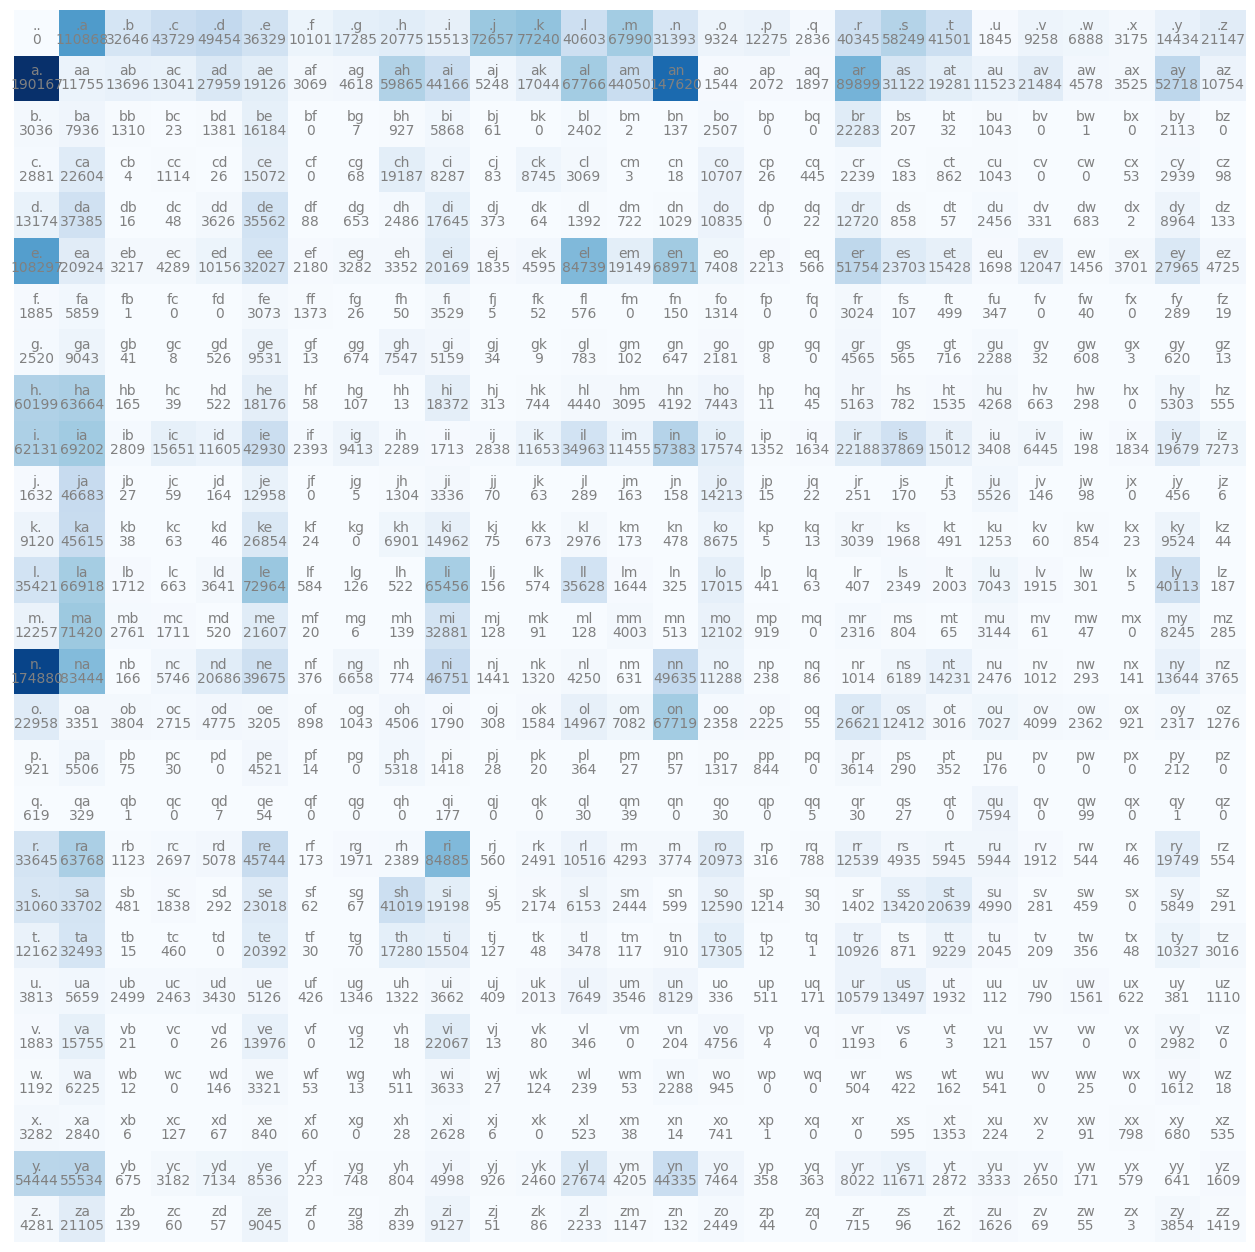

In [9]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = index_to_string[i] + index_to_string[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [10]:
N[0]

tensor([     0, 110868,  32646,  43729,  49454,  36329,  10101,  17285,  20775,
         15513,  72657,  77240,  40603,  67990,  31393,   9324,  12275,   2836,
         40345,  58249,  41501,   1845,   9258,   6888,   3175,  14434,  21147],
       dtype=torch.int32)

In [11]:
# P = N.float()
P = (N + 1).float() # 위의 표를 보면, 'zq', 'fp' 와 같이 카운트가 0인 것들이 있음. 이걸 그대로 사용해서 추후 아래에서 nll을 구할 때, 저 문자열을 갖고 있는 이름이 실제 나타나면 nll 값이 inf로 나온다. log 0 = -inf. 이를 막기 위해 + 1을 함. model smoothing의 개념. 크게 더할 수록 편차들이 줄어든다.

# Count 기반 Bigram. 관찰된 빈도를 확률로 변환한다.
# sum(0, keepdim=True)로 하면 열 합계가 1이 됨, sum(1, keepdim=True)로 하면 행 합계가 1이 됨. 우리가 구하고자 하는 것은 앞 문자가 주어졌을 때 뒷 문자가 나올 확률이므로, 행 합계가 1이 되도록 해야 함.
# keepdim=True를 하지 않으면 P /= P.sum(1)에서 P.sum(1)의 shape이 (27,)이 되어 P의 shape (27, 27)과 broadcasting시 (1, 27)으로 변환되어 의도와 다른 결과가 나옴.
P /= P.sum(1, keepdim=True)

In [12]:
g = torch.Generator().manual_seed(2147483647)  # 이건 고정값 나오도록 사용함

# 확률 분포를 기반으로 이름을 생성한다.
for i in range(10):
  out = []
  ix = 0
  while True:
    p = P[ix]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(index_to_string[ix])
    if ix == 0:
      break
  print(''.join(out))

dexze.
momakurailezityha.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [13]:
# GOAL: maximize likelihood of the data w.r.t. model parameters (statistical modeling)
# equivalent to maximizing the log likelihood (because log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

'''
a, b, c가 발생하는 확률을 고려할 때, a, b, c가 동시에 발생할 확률은 P(a, b, c) = P(a) * P(b) * P(c)로 계산할 수 있다.
헌데, 확률을 * 연산하여 사용하면 값이 작아져서 정밀도 문제가 발생할 수 있다. 따라서 log 특성을 이용한다.

log(a*b*c) = log(a) + log(b) + log(c)
'''


'\na, b, c가 발생하는 확률을 고려할 때, a, b, c가 동시에 발생할 확률은 P(a, b, c) = P(a) * P(b) * P(c)로 계산할 수 있다.\n헌데, 확률을 * 연산하여 사용하면 값이 작아져서 정밀도 문제가 발생할 수 있다. 따라서 log 특성을 이용한다.\n\nlog(a*b*c) = log(a) + log(b) + log(c)\n'

In [14]:
'''
likelihood? 모델이 실제 데이터에 부여한 확률.
'''

log_likelihood = 0.0  # 확률의 곱을 로그의 합으로 계산
n = 0

# for w in ['jungbum']: # 내 이름으로 했더니 nll이 높아진다
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = string_to_index[ch1]  # 현재 문자
    ix2 = string_to_index[ch2]  # 다음 문자
    prob = P[ix1, ix2]  # P: 현재 문자가 주어졌을 때 다음 문자가 나올 확률 행렬, prob: 현재 문자가 주어졌을 때 다음 문자가 나올 확률
    logprob = torch.log(prob) # log(x) from 0 to 1. y: - infinity to 0. https://www.wolframalpha.com/input?i=log%28x%29+from+0+to+1
    log_likelihood += logprob
    n += 1
    # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')  # logprob 확인. 건 수가 너무 많아서 깃에 안올라가서 주석처리함.

  # print(f'{log_likelihood=}')
nll = -log_likelihood  # nll: negative log likelihood
print(f'{nll=}')
print(f'{nll/n}') # log_likelihood 이 높을 수록 좋은 모델이니, nll은 낮을 수록 좋다. 

nll=tensor(14971900.)
2.4654381275177


In [67]:
'''
여기까지는 카운트 기반 확률로 처리했으나,
여기서부터는 weight 행렬 W를 학습시키고 loss를 최소화한다.
'''

# create the training set of bigrams (x,y)
xs = [] # x 값이 주어졌을 때,
ys = [] # 모델은 이상적으로 y 값을 반환해야한다.

for w in words[:1]:
    chs = ['.'] + list(w) + ['.']

    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = string_to_index[ch1]
        ix2 = string_to_index[ch2]

        print(ch1, ch2)

        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
print(f'xs: {xs}')
print(f'ys: {ys}')

. a
a a
a b
b a
a n
n .
xs: tensor([ 0,  1,  1,  2,  1, 14])
ys: tensor([ 1,  1,  2,  1, 14,  0])


In [68]:
import torch.nn.functional as F
# x encoding. one hot? 나머지는 cold, 하나만 hot으로 켜져 있다. 특정 index 값만 1로 표시하고, 나머지는 0으로. 벡터 연산을 위해 변환하는 과정
xenc = F.one_hot(xs, num_classes=27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [69]:
xenc.shape


torch.Size([6, 27])

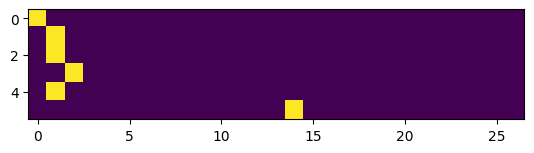

In [70]:
plt.imshow(xenc)

In [83]:
W = torch.randn((27, 27), generator=g, requires_grad=True)
logits = xenc @ W
logits

tensor([[-1.3718, -1.0413,  0.9889,  1.0892,  0.5217, -0.0127, -0.6416,  1.2104,
         -1.5112, -1.1497, -1.4225,  0.5670, -0.6711, -1.2982, -1.3227, -0.4098,
         -1.1908,  0.5080, -0.2305, -0.8732, -1.4523,  1.8300,  1.4958, -0.9854,
         -0.6611, -0.0461,  0.0631],
        [ 1.5308, -1.1742, -0.0733,  0.7706,  0.4130,  0.8056, -0.9783,  0.8150,
         -1.0586,  0.0716, -1.3705, -1.4897,  0.8655,  0.9459, -0.1971, -1.7490,
          1.4255,  1.5681,  1.3190,  1.0370, -0.0503,  0.4925,  0.9007, -1.4403,
          1.1452, -0.6172, -0.7818],
        [ 1.5308, -1.1742, -0.0733,  0.7706,  0.4130,  0.8056, -0.9783,  0.8150,
         -1.0586,  0.0716, -1.3705, -1.4897,  0.8655,  0.9459, -0.1971, -1.7490,
          1.4255,  1.5681,  1.3190,  1.0370, -0.0503,  0.4925,  0.9007, -1.4403,
          1.1452, -0.6172, -0.7818],
        [ 0.2904,  0.5869, -1.6037,  0.7015, -2.2562, -0.0923,  0.1875,  2.2631,
          0.3331,  0.7951,  1.4513, -0.8537,  1.7837,  0.9774,  1.3844,  0.2496

In [ ]:
'''
이제 softmax를 진행한다.
점수화한 logits를 자연상수로 지수화하고 확률을 구한다.
output layer에서 나온 값들을 Probability로 출력(변환) 하는 과정.
output layer가 음수여도, 출력된 Probability는 [0, 1) range 이며 Sum to 1.
'''

In [84]:
# softmax 진행 1
counts = logits.exp()  # logit에서 나온 음수 값을 1미만 양수로 변환, 확률 값을 산출 할 수 있도록, 자연상수 지수로 변환. 
counts

tensor([[0.2536, 0.3530, 2.6884, 2.9719, 1.6849, 0.9874, 0.5264, 3.3548, 0.2206,
         0.3167, 0.2411, 1.7630, 0.5111, 0.2730, 0.2664, 0.6638, 0.3040, 1.6620,
         0.7941, 0.4176, 0.2340, 6.2341, 4.4631, 0.3733, 0.5163, 0.9550, 1.0651],
        [4.6219, 0.3091, 0.9293, 2.1610, 1.5113, 2.2380, 0.3760, 2.2593, 0.3469,
         1.0743, 0.2540, 0.2254, 2.3762, 2.5751, 0.8211, 0.1740, 4.1598, 4.7974,
         3.7398, 2.8206, 0.9510, 1.6364, 2.4614, 0.2369, 3.1431, 0.5394, 0.4576],
        [4.6219, 0.3091, 0.9293, 2.1610, 1.5113, 2.2380, 0.3760, 2.2593, 0.3469,
         1.0743, 0.2540, 0.2254, 2.3762, 2.5751, 0.8211, 0.1740, 4.1598, 4.7974,
         3.7398, 2.8206, 0.9510, 1.6364, 2.4614, 0.2369, 3.1431, 0.5394, 0.4576],
        [1.3370, 1.7985, 0.2012, 2.0168, 0.1047, 0.9118, 1.2062, 9.6126, 1.3953,
         2.2146, 4.2688, 0.4258, 5.9521, 2.6576, 3.9923, 1.2835, 1.6078, 1.5804,
         2.5771, 1.2258, 0.7139, 0.4336, 0.7248, 2.9065, 3.8295, 0.1013, 0.5201],
        [4.6219, 0.3091,

In [85]:
# softmax 진행 2
probs = counts / counts.sum(1, keepdims=True)
probs

tensor([[0.0074, 0.0104, 0.0788, 0.0872, 0.0494, 0.0290, 0.0154, 0.0984, 0.0065,
         0.0093, 0.0071, 0.0517, 0.0150, 0.0080, 0.0078, 0.0195, 0.0089, 0.0487,
         0.0233, 0.0122, 0.0069, 0.1828, 0.1309, 0.0109, 0.0151, 0.0280, 0.0312],
        [0.0979, 0.0065, 0.0197, 0.0458, 0.0320, 0.0474, 0.0080, 0.0479, 0.0074,
         0.0228, 0.0054, 0.0048, 0.0503, 0.0546, 0.0174, 0.0037, 0.0881, 0.1016,
         0.0792, 0.0598, 0.0201, 0.0347, 0.0522, 0.0050, 0.0666, 0.0114, 0.0097],
        [0.0979, 0.0065, 0.0197, 0.0458, 0.0320, 0.0474, 0.0080, 0.0479, 0.0074,
         0.0228, 0.0054, 0.0048, 0.0503, 0.0546, 0.0174, 0.0037, 0.0881, 0.1016,
         0.0792, 0.0598, 0.0201, 0.0347, 0.0522, 0.0050, 0.0666, 0.0114, 0.0097],
        [0.0240, 0.0323, 0.0036, 0.0363, 0.0019, 0.0164, 0.0217, 0.1729, 0.0251,
         0.0398, 0.0768, 0.0077, 0.1071, 0.0478, 0.0718, 0.0231, 0.0289, 0.0284,
         0.0464, 0.0220, 0.0128, 0.0078, 0.0130, 0.0523, 0.0689, 0.0018, 0.0094],
        [0.0979, 0.0065,

In [86]:
'''
위에서 나온 출력 값 들고옴 

. a
a a
a b
b a
a n
n .
xs: tensor([ 0,  1,  1,  2,  1, 14])
ys: tensor([ 1,  1,  2,  1, 14,  0])
'''

probs[0, 1], probs[1, 1], probs[2, 2], probs[3, 1], probs[4, 14], probs[5, 0]

(tensor(0.0104, grad_fn=<SelectBackward0>),
 tensor(0.0065, grad_fn=<SelectBackward0>),
 tensor(0.0197, grad_fn=<SelectBackward0>),
 tensor(0.0323, grad_fn=<SelectBackward0>),
 tensor(0.0174, grad_fn=<SelectBackward0>),
 tensor(0.0143, grad_fn=<SelectBackward0>))

In [87]:
# probs[torch.arange(ys.size(0)), ys] = probs[0, 1], probs[1, 1], probs[2, 2], probs[3, 1], probs[4, 14], probs[5, 0] 
probs[torch.arange(ys.size(0)), ys] # ys.size(0) = 6

tensor([0.0104, 0.0065, 0.0197, 0.0323, 0.0174, 0.0143],
       grad_fn=<IndexBackward0>)

In [88]:
loss = -probs[torch.arange(ys.size(0)), ys].log().mean()
loss


tensor(4.2100, grad_fn=<NegBackward0>)

In [89]:
# backward pass
W.grad = None # set to zero the gradient
loss.backward() # 역전파 실행
W.data += -0.1 + W.grad
loss


tensor(4.2100, grad_fn=<NegBackward0>)

In [ ]:
'''
recap. 최종 정리.
'''

In [94]:
# create the dataset
xs, ys = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = string_to_index[ch1]
    ix2 = string_to_index[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initialize the 'network'
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

xs length: 6072714, xs: tensor([ 0,  1,  1,  ..., 25, 26, 24])
number of examples:  6072714


In [96]:
# gradient descent
for k in range(30):
  
  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
  # print(f'xenc.shape: {xenc.shape}') # xenc.shape: torch.Size([6072714, 27])
  logits = xenc @ W # predict log-counts
  # print(f'logits shape: {logits.shape}') # logits shape: torch.Size([6072714, 27])
  counts = logits.exp() # counts, equivalent to N
  probs = counts / counts.sum(1, keepdims=True) # probabilities for next character

  '''
  여기서 Regularization 개념이 나온다.

  count 기반 모델을 만들 때, N 이 아닌 (N + k) 로 분포를 제어했음. k가 클 수록 균등, 평평해짐.
  P = (N + 1).float()
  P /= P.sum(1, keepdims=True)

  여기서는 w를 0에 가까울 수록 균등해지는 특성을 이용한다. w가 전부 0 이라면, 다음 문자열에 동일한 확률이 부여됨.

  Weight가 작아지도록 Loss에 수식을 더해 W 값이 커지는걸 억제한다. 
  Weight가 작아지는 것이 Bigram의 확률 분포와 어떤 관계가 있는가?

  W가 크다는건, 학습된 데이터 기반에 Logit 점수를 크게 준다는 것. 학습된 데이터가 아닌 데이터에서는 답을 맞추지 못할 가능성도 올라감.
  Regularization란 학습 데이터에 존재하는 패턴만으로 지나친 확신을 하지 않도록 하는 것.

  0.01은 Regularization Strength를 조절하는 파라미터.
  너무 크면, 확률이 과도하게 균등해짐. 너무 작으면, 과적화 해결이 미비해짐.

  Training Loss를 최소화하는 것이 머신러닝의 최종 목적이 아니다.

  궁극적인 목적은 학습에 사용하지 않은 새로운 데이터에서도 높은 예측 성능을 보여야 함 - Generalization(일반화)
  Regularization은 일반화 성능을 개선하기 위해 사용하는 대표적인 방법 중 하나
  '''
  loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()  # 
  print(loss.item())
  
  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()
  
  # update
  W.data += -50 * W.grad

2.527132034301758
2.524517297744751
2.5220694541931152
2.5197746753692627
2.5176196098327637
2.515594244003296
2.5136876106262207
2.5118916034698486
2.5101966857910156
2.508596420288086
2.5070834159851074
2.5056509971618652
2.5042943954467773
2.5030081272125244
2.501786708831787
2.5006258487701416
2.4995224475860596
2.498471975326538
2.4974708557128906
2.496516704559326
2.495605945587158
2.494736433029175
2.4939053058624268
2.493109941482544
2.49234938621521
2.4916203022003174
2.4909212589263916
2.4902515411376953
2.4896080493927
2.4889910221099854


In [99]:
# final - 결과는 거의 유사하게 나온다.
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    # p = P[ix]
    # ----------
    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(index_to_string[ix])
    if ix == 0:
      break
  print(''.join(out))

dexze.
momakurailezityha.
konimittain.
llayn.
ka.


In [103]:
# BEFORE: Count 기반 확률
P_count = P

# NOW: Neural Network 기반 확률
P_nn = torch.softmax(W.detach(), dim=1)

# 두 행렬의 Shape
print(P_count.shape)
print(P_nn.shape)

# 모든 확률이 거의 같은지 확인
print(torch.allclose(P_count, P_nn, atol=1e-5))

# 가장 큰 확률 차이
print((P_count - P_nn).abs().max().item())

# 현재 문자가 'a'일 때 확률 분포 비교
ix = string_to_index['a']
print("a: Count:", P_count[ix])
print("a: Neural Network:", P_nn[ix])

# 현재 문자가 'b'일 때 확률 분포 비교
ix = string_to_index['e']
print("e: Count:", P_count[ix])
print("e: Neural Network:", P_nn[ix])

torch.Size([27, 27])
torch.Size([27, 27])
False
0.5640087127685547
a: Count: tensor([0.2068, 0.0128, 0.0149, 0.0142, 0.0304, 0.0208, 0.0033, 0.0050, 0.0651,
        0.0480, 0.0057, 0.0185, 0.0737, 0.0479, 0.1605, 0.0017, 0.0023, 0.0021,
        0.0978, 0.0338, 0.0210, 0.0125, 0.0234, 0.0050, 0.0038, 0.0573, 0.0117])
a: Neural Network: tensor([0.2061, 0.0126, 0.0148, 0.0140, 0.0302, 0.0206, 0.0041, 0.0052, 0.0648,
        0.0477, 0.0060, 0.0184, 0.0733, 0.0476, 0.1600, 0.0028, 0.0033, 0.0028,
        0.0974, 0.0336, 0.0208, 0.0124, 0.0232, 0.0053, 0.0045, 0.0570, 0.0116])
e: Count: tensor([0.2006, 0.0388, 0.0060, 0.0079, 0.0188, 0.0593, 0.0040, 0.0061, 0.0062,
        0.0374, 0.0034, 0.0085, 0.1570, 0.0355, 0.1278, 0.0137, 0.0041, 0.0011,
        0.0959, 0.0439, 0.0286, 0.0031, 0.0223, 0.0027, 0.0069, 0.0518, 0.0088])
e: Neural Network: tensor([0.1996, 0.0382, 0.0066, 0.0084, 0.0185, 0.0587, 0.0046, 0.0068, 0.0062,
        0.0369, 0.0051, 0.0086, 0.1560, 0.0350, 0.1269, 0.0134, 0.0053, 